# Car Price Prediction Using Machine Learning

## Project Overview

The aim of this project is to develop a Machine Learning model that predicts the selling price of used cars based on various features such as brand, manufacturing year, mileage, engine capacity, maximum power, fuel type, transmission and ownership details.

The project involves data exploration, data cleaning, feature engineering, exploratory data analysis, model building and performance evaluation.

Two regression algorithms, Linear Regression and Random Forest Regressor, will be implemented and compared to identify the best-performing model.

## Objectives

- Explore and understand the used car dataset.
- Clean the dataset by handling missing values and duplicate records.
- Perform feature engineering to create useful features.
- Visualize patterns and relationships using Exploratory Data Analysis.
- Prepare categorical and numerical data for Machine Learning.
- Train and evaluate regression models.
- Identify the best-performing model for car price prediction.

## 1. Importing Libraries and Loading the Dataset

The required Python libraries are imported to perform data manipulation, numerical operations, visualization and Machine Learning.

The dataset used in this project is **Car details v3.csv**. It contains information about used cars, including their names, manufacturing years, selling prices, mileage, engine capacity, fuel type and other specifications.

The dataset is loaded into a Pandas DataFrame for further analysis.

In [1]:
# Importing libraries for data manipulation and numerical operations
import pandas as pd
import numpy as np

# Importing libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Importing libraries for splitting data and building regression models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Importing evaluation metrics for regression models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Loading the car details dataset
df = pd.read_csv("Car details v3.csv")

# Displaying the first five rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## 2. Understanding the Dataset

Before performing data preprocessing, we need to understand the structure and contents of the dataset.

In this step, we will:

- Check the number of rows and columns.
- Examine column names, data types and non-null values.
- Identify missing values in each column.
- Check the number of duplicate records.
- Generate descriptive statistics for numerical columns.
- Explore the unique values in categorical columns.

This initial inspection helps identify the data quality issues that need to be addressed before model building.

In [3]:
# Displaying the number of rows and columns in the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (8128, 13)


In [4]:
# Displaying information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [5]:
# Checking the number of missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


In [6]:
# Checking the number of duplicate records
print("Number of Duplicate Records:", df.duplicated().sum())

Number of Duplicate Records: 1202


## 3. Data Cleaning

Data cleaning is an important step in preparing the dataset for Machine Learning.

In this stage, duplicate records are removed to avoid unnecessary repetition in the dataset.

We will also inspect categorical values, column data types and measurement columns to identify inconsistencies and prepare the data for further processing.

In [7]:
# Removing duplicate records
df = df.drop_duplicates()

# Checking the updated dataset shape
print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (6926, 13)


In [8]:
# Checking for duplicate records after removal
print("Remaining Duplicate Records:", df.duplicated().sum())

Remaining Duplicate Records: 0


In [9]:
# Displaying descriptive statistics of numerical columns
df.describe()

,year,selling_price,km_driven,seats
count,6926.000000,6.926000e+03,6.926000e+03,6718.000000
mean,2013.420300,5.172707e+05,7.399568e+04,5.434653
std,4.078286,5.197670e+05,5.835810e+04,0.984230
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.500000e+05,4.000000e+04,5.000000
50%,2014.000000,4.000000e+05,7.000000e+04,5.000000
75%,2017.000000,6.335000e+05,1.000000e+05,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [10]:
# Displaying unique values in categorical columns
categorical_columns = ['fuel', 'seller_type', 'transmission', 'owner']

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())


Unique values in fuel:
<StringArray>
['Diesel', 'Petrol', 'LPG', 'CNG']
Length: 4, dtype: str

Unique values in seller_type:
<StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str

Unique values in transmission:
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

Unique values in owner:
<StringArray>
[         'First Owner',         'Second Owner',          'Third Owner',
 'Fourth & Above Owner',       'Test Drive Car']
Length: 5, dtype: str


In [11]:
# Displaying the number of unique car names
print("Number of Unique Car Names:", df['name'].nunique())

# Displaying the first 20 unique car names
print("\nSample Car Names:")
print(df['name'].unique()[:20])

Number of Unique Car Names: 2058

Sample Car Names:
<StringArray>
[              'Maruti Swift Dzire VDI',
         'Skoda Rapid 1.5 TDI Ambition',
             'Honda City 2017-2020 EXi',
            'Hyundai i20 Sportz Diesel',
               'Maruti Swift VXI BSIII',
        'Hyundai Xcent 1.2 VTVT E Plus',
         'Maruti Wagon R LXI DUO BSIII',
                   'Maruti 800 DX BSII',
                     'Toyota Etios VXD',
 'Ford Figo Diesel Celebration Edition',
      'Renault Duster 110PS Diesel RxL',
                        'Maruti Zen LX',
               'Maruti Swift Dzire VDi',
                 'Maruti Swift 1.3 VXi',
             'Maruti Wagon R LXI Minor',
 'Mahindra KUV 100 mFALCON G80 K8 5str',
               'Maruti Ertiga SHVS VDI',
            'Hyundai i20 1.4 CRDi Asta',
                       'Maruti Alto LX',
  'Hyundai i20 2015-2017 Asta 1.4 CRDi']
Length: 20, dtype: str


In [12]:
# Checking categorical values for leading and trailing spaces
for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Values with extra spaces:", 
          (df[column] != df[column].str.strip()).sum())


Column: fuel
Values with extra spaces: 0

Column: seller_type
Values with extra spaces: 0

Column: transmission
Values with extra spaces: 0

Column: owner
Values with extra spaces: 0


In [13]:
# Displaying the data types of all columns
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64
dtype: object


### 3.1 Handling Measurement Columns

Some numerical columns contain measurement units along with their values.

For example:
- Mileage contains values followed by `kmpl` or `km/kg`.
- Engine contains values followed by `CC`.
- Maximum power contains values followed by `bhp`.
- Torque contains different units and formats.

To make the dataset suitable for numerical analysis, we will extract numerical values from the mileage, engine and maximum power columns and convert them into floating-point values.

The torque column will be inspected separately because its inconsistent formats make direct numerical conversion difficult.

In [14]:
# Displaying sample values from columns containing measurement units
measurement_columns = ['mileage', 'engine', 'max_power', 'torque']

for column in measurement_columns:
    print(f"\nSample values in {column}:")
    print(df[column].dropna().head(5).tolist())


Sample values in mileage:
['23.4 kmpl', '21.14 kmpl', '17.7 kmpl', '23.0 kmpl', '16.1 kmpl']

Sample values in engine:
['1248 CC', '1498 CC', '1497 CC', '1396 CC', '1298 CC']

Sample values in max_power:
['74 bhp', '103.52 bhp', '78 bhp', '90 bhp', '88.2 bhp']

Sample values in torque:
['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)']


In [15]:
# Extracting numerical values from mileage and converting to float
df['mileage'] = df['mileage'].str.extract(r'(\d+\.?\d*)').astype(float)

# Extracting numerical values from engine and converting to float
df['engine'] = df['engine'].str.extract(r'(\d+\.?\d*)').astype(float)

# Extracting numerical values from max_power and converting to float
df['max_power'] = df['max_power'].str.extract(r'(\d+\.?\d*)').astype(float)

# Displaying the updated data types
print(df[['mileage', 'engine', 'max_power']].dtypes)

mileage      float64
engine       float64
max_power    float64
dtype: object


In [16]:
# Displaying all unique torque values for inspection
print("Number of Unique Torque Values:", df['torque'].nunique())

# Displaying sample torque values
print("\nSample Torque Values:")
print(df['torque'].dropna().unique()[:20])

Number of Unique Torque Values: 441

Sample Torque Values:
<StringArray>
[          '190Nm@ 2000rpm',      '250Nm@ 1500-2500rpm',
    '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm',
    '11.5@ 4,500(kgm@ rpm)',        '113.75nm@ 4000rpm',
     '7.8@ 4,500(kgm@ rpm)',            '59Nm@ 2500rpm',
      '170Nm@ 1800-2400rpm',           '160Nm@ 2000rpm',
           '248Nm@ 2250rpm',            '78Nm@ 4500rpm',
            '84Nm@ 3500rpm',      '115Nm@ 3500-3600rpm',
           '200Nm@ 1750rpm',            '62Nm@ 3000rpm',
    '219.7Nm@ 1500-2750rpm',           '114Nm@ 3500rpm',
           '115Nm@ 4000rpm',            '69Nm@ 3500rpm']
Length: 20, dtype: str


In [17]:
# Removing the torque column due to inconsistent measurement formats
df = df.drop(columns=['torque'])

# Displaying the updated dataset columns
print("Updated Dataset Columns:")
print(df.columns.tolist())

Updated Dataset Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats']


### 3.2 Handling Missing Values

After converting the measurement columns into numerical formats, some missing values may be present.

In this step, we will identify missing values and handle them using median imputation.

The median of each numerical column is used to fill its missing values. This approach helps retain the available records while reducing the influence of extreme values.

The torque column has already been removed because of its inconsistent measurement formats.

In [18]:
# Checking missing values in the updated dataset
print("Missing Values After Data Conversion:")
print(df.isnull().sum())

Missing Values After Data Conversion:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        206
seats            208
dtype: int64


In [19]:
# Filling missing numerical values with their respective column medians
numerical_columns = ['mileage', 'engine', 'max_power', 'seats']

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

# Checking missing values after handling them
print("Missing Values After Imputation:")
print(df.isnull().sum())

Missing Values After Imputation:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64


### 3.3 Verifying the Cleaned Dataset

After handling missing values and removing duplicate records, we will verify the final dataset.

We will check:
- The updated dataset dimensions.
- The total number of remaining missing values.
- The total number of remaining duplicate records.

This ensures that the dataset is ready for feature engineering and further analysis.

In [20]:
# Displaying the final dataset dimensions
print("Final Dataset Shape:", df.shape)

# Checking for remaining missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Checking for remaining duplicate records
print("Total Duplicate Records:", df.duplicated().sum())

Final Dataset Shape: (6926, 12)

Total Missing Values: 0
Total Duplicate Records: 0


## 4. Feature Engineering

Feature engineering is the process of creating new features from existing data to improve the usefulness of the dataset for Machine Learning.

In this project, we will create two additional features:

1. **Car Age:** Calculated by subtracting the manufacturing year from the current year (2026).
2. **Brand:** Extracted from the car name to identify the manufacturer.

These features provide additional information that may help the regression models predict used car selling prices.

In [21]:
# Calculating the age of each car
current_year = 2026
df['car_age'] = current_year - df['year']

# Displaying car names, manufacturing years and calculated ages
df[['name', 'year', 'car_age']].head()

,name,year,car_age
0,Maruti Swift Dzire VDI,2014,12
1,Skoda Rapid 1.5 TDI Ambition,2014,12
2,Honda City 2017-2020 EXi,2006,20
3,Hyundai i20 Sportz Diesel,2010,16
4,Maruti Swift VXI BSIII,2007,19


### 4.1 Checking Extracted Car Brands

The car brand is extracted from the original car name column.

Some manufacturers have multi-word brand names, such as Land Rover and Ashok Leyland. These names are corrected separately to ensure that they are represented accurately.

In this step, we will examine the number of unique brands and the number of records belonging to each brand.

In [22]:
# Extracting car brands from the name column
df['brand'] = df['name'].str.split().str[0]

# Displaying car names and their extracted brands
df[['name', 'brand']].head(10)

,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Honda City 2017-2020 EXi,Honda
3,Hyundai i20 Sportz Diesel,Hyundai
4,Maruti Swift VXI BSIII,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai
6,Maruti Wagon R LXI DUO BSIII,Maruti
7,Maruti 800 DX BSII,Maruti
8,Toyota Etios VXD,Toyota
9,Ford Figo Diesel Celebration Edition,Ford


In [23]:
# Correcting incomplete brand names
df.loc[df['brand'] == 'Land', 'brand'] = 'Land Rover'
df.loc[df['brand'] == 'Ashok', 'brand'] = 'Ashok Leyland'

# Displaying the corrected brand names
print("Corrected Brand Counts:")
print(df['brand'].value_counts().loc[['Land Rover', 'Ashok Leyland']])

Corrected Brand Counts:
brand
Land Rover       3
Ashok Leyland    1
Name: count, dtype: int64


In [24]:
# Verifying the corrected car brands
df.loc[
    df['brand'].isin(['Land Rover', 'Ashok Leyland']),
    ['name', 'brand']
].drop_duplicates()

,name,brand
135,Land Rover Discovery Sport TD4 SE,Land Rover
2137,Land Rover Freelander 2 TD4 HSE,Land Rover
4011,Ashok Leyland Stile LE,Ashok Leyland
6724,Land Rover Range Rover Evoque 2.2L Pure,Land Rover


In [25]:
# Displaying the number of unique car brands
print("Number of Unique Brands:", df['brand'].nunique())

# Displaying the number of cars belonging to each brand
print("\nCar Count by Brand:")
print(df['brand'].value_counts())

Number of Unique Brands: 32

Car Count by Brand:
brand
Maruti           2165
Hyundai          1267
Mahindra          723
Tata              647
Honda             362
Ford              361
Toyota            357
Chevrolet         216
Renault           206
Volkswagen        174
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Fiat               44
Audi               33
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Force               4
Ambassador          4
Isuzu               4
Land Rover          3
MG                  3
Daewoo              3
Kia                 3
Lexus               1
Ashok Leyland       1
Opel                1
Peugeot             1
Name: count, dtype: int64


### 4.2 Verifying Engineered Features

After creating the `car_age` and `brand` features, we will verify whether they have been added correctly.

The original car name, manufacturing year, calculated car age and extracted brand are displayed together for inspection.

In [26]:
# Displaying the updated dataset with engineered features
df[['name', 'year', 'car_age', 'brand']].head(10)

,name,year,car_age,brand
0,Maruti Swift Dzire VDI,2014,12,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,12,Skoda
2,Honda City 2017-2020 EXi,2006,20,Honda
3,Hyundai i20 Sportz Diesel,2010,16,Hyundai
4,Maruti Swift VXI BSIII,2007,19,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,2017,9,Hyundai
6,Maruti Wagon R LXI DUO BSIII,2007,19,Maruti
7,Maruti 800 DX BSII,2001,25,Maruti
8,Toyota Etios VXD,2011,15,Toyota
9,Ford Figo Diesel Celebration Edition,2013,13,Ford


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the distribution of data, identify patterns and examine relationships between different variables.

In this project, we will use visualizations to explore:

1. Distribution of selling prices using a histogram.
2. Selling price across different fuel types using a box plot.
3. Relationship between car age and selling price using a scatter plot.

These visualizations help us understand the factors that may influence the resale value of used cars.

### 5.1 Distribution of Selling Prices

A histogram is used to visualize the distribution of selling prices in the dataset.

This visualization helps us understand how frequently different price ranges occur and whether the selling prices are evenly distributed or skewed.

The Kernel Density Estimate (KDE) curve provides an additional view of the overall distribution.

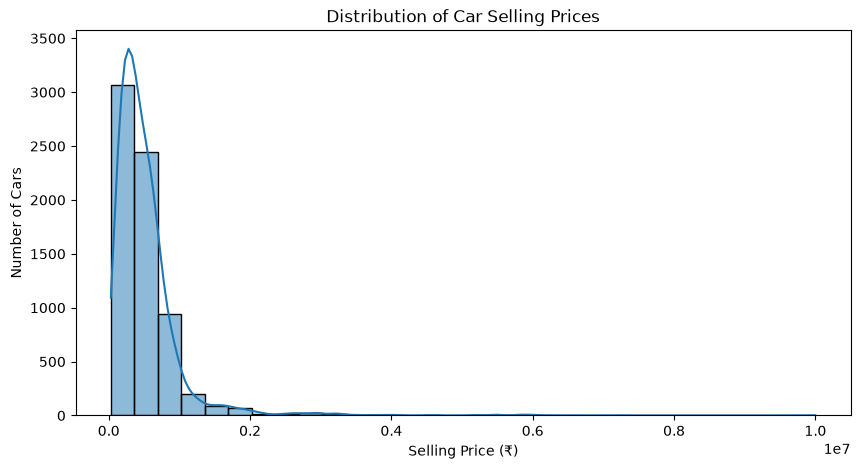

In [27]:
# Plotting the distribution of car selling prices
plt.figure(figsize=(10, 5))

sns.histplot(df['selling_price'], bins=30, kde=True)

# Adding chart title and axis labels
plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price (₹)')
plt.ylabel('Number of Cars')

# Displaying the plot
plt.show()

### 5.2 Selling Price vs Fuel Type

A box plot is used to compare the selling prices of cars belonging to different fuel categories.

It helps us examine the median selling price, spread of prices and presence of outliers for each fuel type.

This analysis provides an understanding of how selling prices vary across different fuel categories.

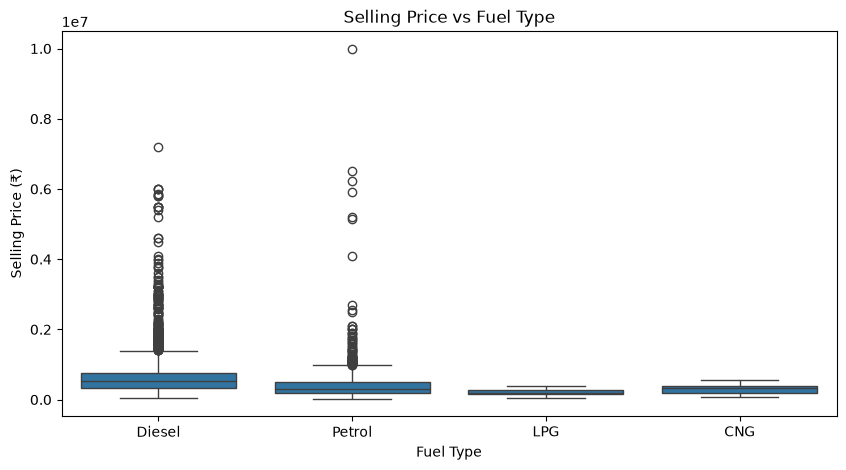

In [28]:
# Comparing selling prices across different fuel types
plt.figure(figsize=(10, 5))

sns.boxplot(x='fuel', y='selling_price', data=df)

# Adding chart title and axis labels
plt.title('Selling Price vs Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (₹)')

# Displaying the plot
plt.show()

### 5.3 Selling Price vs Car Age

A scatter plot is used to examine the relationship between the age of a car and its selling price.

Each point represents an individual car. By observing the distribution of points, we can understand whether car age has a positive or negative relationship with selling price.

This analysis helps identify how vehicle age may influence its resale value.

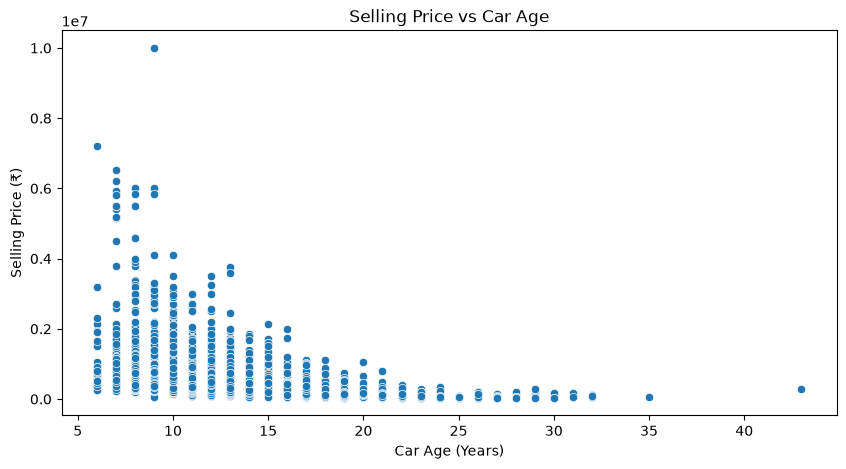

In [29]:
# Visualizing the relationship between car age and selling price
plt.figure(figsize=(10, 5))

sns.scatterplot(x='car_age', y='selling_price', data=df)

# Adding chart title and axis labels
plt.title('Selling Price vs Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price (₹)')

# Displaying the plot
plt.show()

## 6. Feature Correlation Analysis

Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

In this step, we will calculate the correlation matrix and visualize it using a heatmap.

The heatmap helps identify:
- Features that have a strong positive relationship with selling price.
- Features that have a negative relationship with selling price.
- Features that are highly correlated with one another.

This analysis helps us understand the numerical relationships in the dataset before preparing it for model training.

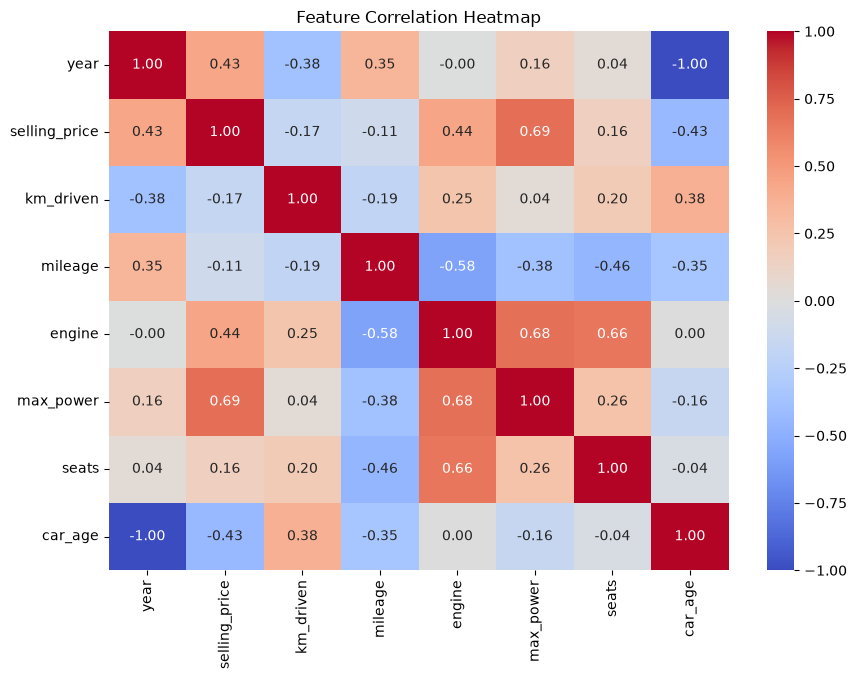

In [30]:
# Selecting numerical columns for correlation analysis
numerical_data = df.select_dtypes(include=['int64', 'float64'])

# Calculating the correlation matrix
correlation_matrix = numerical_data.corr()

# Plotting the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

# Adding chart title
plt.title('Feature Correlation Heatmap')

# Displaying the plot
plt.show()

## 7. Data Preprocessing for Machine Learning

Before training the regression models, the dataset must be prepared in a suitable format.

The original `name` column is removed because the brand has already been extracted from it.

The `year` column is also removed because the car's age has already been calculated and stored in the `car_age` feature.

A separate dataset is created for Machine Learning while retaining the target variable, `selling_price`.

In [31]:
# Creating a separate dataset by removing unnecessary columns
model_df = df.drop(columns=['name', 'year'])

# Displaying the updated dataset
print("Updated Dataset Shape:", model_df.shape)

# Displaying the remaining columns
print("\nRemaining Columns:")
print(model_df.columns.tolist())

Updated Dataset Shape: (6926, 12)

Remaining Columns:
['selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'car_age', 'brand']


### 7.1 Encoding Categorical Variables

Machine Learning regression algorithms require numerical input features.

The dataset contains categorical variables such as fuel, seller type, transmission, owner and brand.

In this step, One-Hot Encoding is applied using Pandas `get_dummies()` function to convert these categorical values into numerical columns.

The parameter `drop_first=True` removes the first category from each encoded variable to avoid redundant dummy variables.

In [32]:
# Identifying categorical columns for One-Hot Encoding
categorical_columns = ['fuel', 'seller_type', 'transmission', 'owner', 'brand']

# Applying One-Hot Encoding to categorical features
model_df_encoded = pd.get_dummies(
    model_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Displaying the updated dataset dimensions
print("Dataset Shape After Encoding:", model_df_encoded.shape)

# Displaying the first five rows
model_df_encoded.head()

Dataset Shape After Encoding: (6926, 48)


,selling_price,km_driven,mileage,engine,max_power,seats,car_age,fuel_Diesel,fuel_LPG,fuel_Petrol,...,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Peugeot,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,450000,145500,23.40,1248.0,74.00,5.0,12,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,370000,120000,21.14,1498.0,103.52,5.0,12,1,0,0,...,0,0,0,0,0,1,0,0,0,0
2,158000,140000,17.70,1497.0,78.00,5.0,20,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,225000,127000,23.00,1396.0,90.00,5.0,16,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,130000,120000,16.10,1298.0,88.20,5.0,19,0,0,1,...,0,0,0,0,0,0,0,0,0,0


### 7.2 Separating Features and Target Variable

The dataset is divided into input features and a target variable.

- **X (Features):** Contains the car-related attributes used to predict the selling price.
- **y (Target):** Contains the actual selling prices that the model needs to predict.

The `selling_price` column is separated from the input features because it is the value we want the regression models to estimate.

In [33]:
# Separating input features by removing the target column
X = model_df_encoded.drop(columns=['selling_price'])

# Storing selling price as the target variable
y = model_df_encoded['selling_price']

# Displaying the dimensions of features and target
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6926, 47)
Target Shape: (6926,)


### 7.3 Train-Test Split

The dataset is divided into training and testing sets using Scikit-learn's `train_test_split()` function.

The split is performed as follows:

- 80% of the data is used for training.
- 20% of the data is used for testing.

The `random_state=42` parameter ensures that the same split can be reproduced when the code is executed again.

The training data is used to build the models, while the testing data is used to evaluate their performance on unseen records.

In [34]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Displaying the dimensions of training and testing data
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (5540, 47)
Testing Features Shape: (1386, 47)
Training Target Shape: (5540,)
Testing Target Shape: (1386,)


## 8. Model Building

In this stage, two supervised Machine Learning regression algorithms are trained to predict used car selling prices.

The algorithms selected for this project are:

1. Linear Regression
2. Random Forest Regressor

Both models are trained using the same training dataset. Their predictions will later be evaluated and compared to identify the better-performing model.

### 8.1 Linear Regression

Linear Regression is a supervised Machine Learning algorithm used to predict continuous numerical values.

It learns the relationship between the input features and the target variable by fitting a linear equation to the training data.

In this step, we will train the Linear Regression model using the training dataset and generate predictions for the testing dataset.

In [35]:
# Creating the Linear Regression model
linear_model = LinearRegression()

# Training the model using training data
linear_model.fit(X_train, y_train)

# Predicting selling prices using testing data
linear_predictions = linear_model.predict(X_test)

# Displaying sample predicted prices
print("Sample Predicted Selling Prices:")
print(linear_predictions[:10])

Sample Predicted Selling Prices:
[ 600504.28596656 1101256.74219487  731129.17338214   55945.87184172
  751478.62330936  766250.07161803  284660.76871418   -3369.02019482
  222966.7011373   444427.17962437]


### 8.2 Random Forest Regression

Random Forest Regressor is an ensemble Machine Learning algorithm that combines multiple decision trees to generate predictions.

Each decision tree makes a prediction, and the results are combined to produce the final predicted value.

Random Forest can capture complex relationships between input features and selling prices.

In this step, we will train the Random Forest Regressor using 100 decision trees and generate predictions for the testing dataset.

In [36]:
# Creating the Random Forest Regressor model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Training the model using training data
random_forest_model.fit(X_train, y_train)

# Predicting selling prices using testing data
rf_predictions = random_forest_model.predict(X_test)

# Displaying sample predicted prices
print("Sample Predicted Selling Prices:")
print(rf_predictions[:10])

Sample Predicted Selling Prices:
[ 611709.96       1075316.48666667  840086.66666667  143125.79
  703960.          948843.33333333  291977.66666667  239893.27333333
  238319.98        527599.98      ]


## 9. Model Evaluation

After training both regression models, their performance is evaluated using three commonly used regression metrics.

1. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted selling prices. A lower value indicates better performance.

2. **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors. It gives greater importance to larger errors. A lower value is better.

3. **R-squared (R²):** Measures how much of the variation in the target variable is explained by the model. A value closer to 1 generally indicates better predictive performance.

These metrics help us compare the accuracy of Linear Regression and Random Forest Regressor.

In [37]:
# Evaluating the Linear Regression model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Evaluating the Random Forest Regressor model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Displaying the evaluation results
print("Linear Regression Performance:")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

print("\nRandom Forest Regression Performance:")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Linear Regression Performance:
MAE: 140172.1508067685
RMSE: 274765.7269172515
R2 Score: 0.6557740092494059

Random Forest Regression Performance:
MAE: 72638.14352439933
RMSE: 128585.48684358975
R2 Score: 0.9246119610809522


### 9.1 Model Performance Comparison

The evaluation metrics of Linear Regression and Random Forest Regressor are organized into a comparison table.

By comparing MAE, RMSE and R² scores, we can identify which model performs better on the testing dataset.

A model with lower MAE and RMSE and a higher R² score is generally preferred.

In [38]:
# Creating a comparison table for both regression models
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [linear_mae, rf_mae],
    'RMSE': [linear_rmse, rf_rmse],
    'R2 Score': [linear_r2, rf_r2]
})

# Displaying model performance comparison
model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,140172.150807,274765.726917,0.655774
1,Random Forest,72638.143524,128585.486844,0.924612


## 10. Feature Importance Analysis

Feature importance analysis helps identify which input features contribute most to the predictions made by the Random Forest Regressor.

In this step, we will extract the feature importance values from the trained Random Forest model.

The importance values are sorted in descending order, and the top 15 features are visualized using a bar plot.

This analysis helps us understand which car attributes have the greatest influence on the model's predictions.

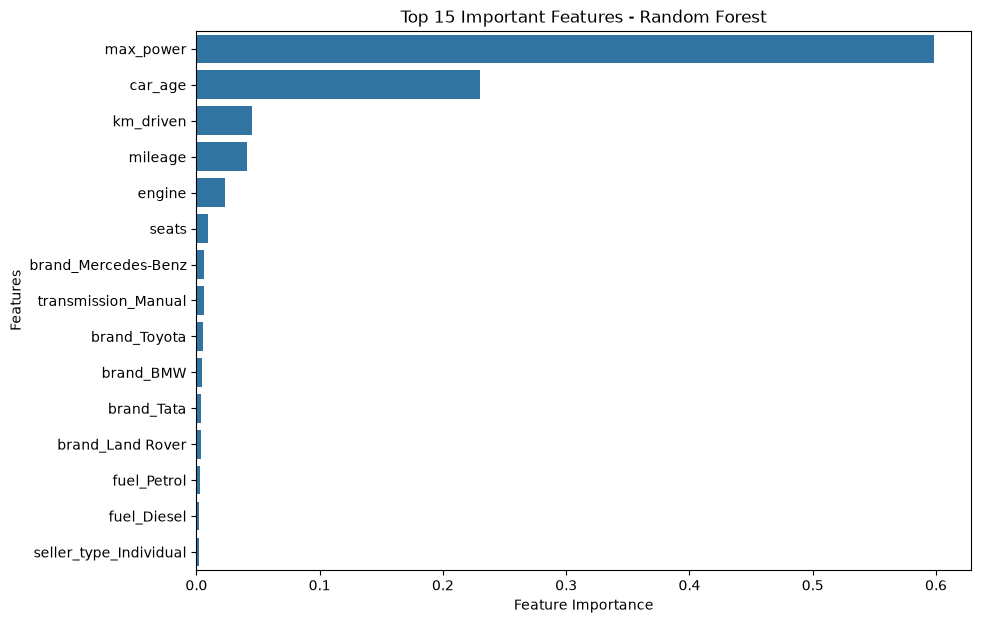

In [39]:
# Extracting feature importance values from the Random Forest model
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': random_forest_model.feature_importances_
})

# Sorting features by importance in descending order
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Selecting the top 15 important features
top_features = feature_importance.head(15)

# Plotting the feature importance chart
plt.figure(figsize=(10, 7))

sns.barplot(
    x='Importance',
    y='Feature',
    data=top_features
)

# Adding chart title and axis labels
plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

# Displaying the plot
plt.show()

## 11. Final Model Summary

Based on the evaluation results, the Random Forest Regressor is selected as the best-performing model.

In this step, we will summarize its final performance using MAE, RMSE and R² scores.

We will also display the number of input features used by the model to generate predictions.

In [40]:
# Displaying the best-performing model
print("Best Performing Model: Random Forest Regressor")

# Displaying the final evaluation metrics
print("\nFinal Model Performance:")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

# Displaying the number of features used by the model
print("\nNumber of Input Features:", X_train.shape[1])

Best Performing Model: Random Forest Regressor

Final Model Performance:
MAE: 72638.14352439933
RMSE: 128585.48684358975
R2 Score: 0.9246119610809522

Number of Input Features: 47


## Conclusion

This project successfully developed a Machine Learning model to predict the selling prices of used cars based on various features such as brand, car age, mileage, engine capacity, maximum power, fuel type and transmission.

The dataset was cleaned by handling missing values, removing duplicate records and converting measurement columns into numerical formats. Feature engineering was performed to extract car brands and calculate car age. Exploratory Data Analysis was conducted to understand price distributions and relationships between different car features.

Two regression algorithms, Linear Regression and Random Forest Regressor, were implemented and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R-squared (R²).

Among the two models, the Random Forest Regressor achieved the best performance with an R² score of **0.9246 (92.46%)**, an MAE of approximately **₹72,638** and an RMSE of approximately **₹1,28,585**.

Feature importance analysis identified maximum power and car age as the most influential features in predicting used car prices.

Overall, this project demonstrates how Machine Learning techniques can be applied to estimate used car prices and understand the factors influencing their resale value.